# EP Integrado — EDA e Data Storytelling: Ebola na África Subsaariana (2014–2026)
**Unimpacta · Prof. Msc. Kyung Moo Kim** — consultoria de dados para a OMS.

Estrutura: Etapa 1 (saneamento) → Etapa 2 (EDA) → Etapa 3 (inferência, IC 95% e regressão) → clusterização → Etapa 4 (recomendações).

**Limitações da base (declaradas desde já):** a planilha tem 1.200 notificações e 10 colunas. Não há colunas de óbitos, população, densidade, indicadores socioeconômicos nem leitos de UTI. Por isso: (i) óbitos são *estimados* como casos × letalidade; (ii) a população por país é uma premissa externa aproximada (~2020); (iii) `Leitos_Por_10k_Hab` (leitos hospitalares) é usado como proxy de capacidade assistencial.

In [25]:
import json
import re
import unicodedata
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, silhouette_score
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
COR = "#B22222"   # cor de destaque
COR2 = "#2F4B7C"
ARQUIVO = "ebola_historico_africa_subsaariana_2014_2026.xlsx"
FIGS = Path("figs")
FIGS.mkdir(exist_ok=True)
METRICAS = {}


def salvar(fig, nome):
    """Salva a figura em alta resolução para o relatório."""
    fig.savefig(FIGS / f"{nome}.png", dpi=170, bbox_inches="tight")

## Etapa 1 — Ingestão, saneamento e auditoria

In [26]:
def normalizar_coluna(nome):
    """Remove acentos/caracteres especiais e padroniza separadores."""
    nome = unicodedata.normalize("NFKD", str(nome)).encode("ascii", "ignore").decode()
    return re.sub(r"[^0-9A-Za-z]+", "_", nome.strip()).strip("_")


bruto = pd.read_excel(ARQUIVO)
bruto.columns = [normalizar_coluna(c) for c in bruto.columns]
bruto["Data_Notificacao"] = pd.to_datetime(bruto["Data_Notificacao"])
bruto["Pais"] = bruto["Pais"].str.strip()
bruto = bruto.sort_values("Data_Notificacao").reset_index(drop=True)

print("Dimensão:", bruto.shape)
print("Período:", bruto["Data_Notificacao"].min().date(), "→", bruto["Data_Notificacao"].max().date())
print("IDs duplicados:", bruto["ID_Registro"].duplicated().sum())
print("\nTipos:\n", bruto.dtypes)
bruto.head()

Dimensão: (1200, 10)
Período: 2014-01-01 → 2026-09-30
IDs duplicados: 0

Tipos:
 ID_Registro                            str
Data_Notificacao            datetime64[us]
Ano                                  int64
Pais                                   str
Idade_Paciente                       int64
Dias_Ate_Internacao                float64
R0_Local_Estimado                  float64
Leitos_Por_10k_Hab                 float64
Casos_Confirmados_Semana             int64
Taxa_Letalidade_Pct                float64
dtype: object


,ID_Registro,Data_Notificacao,Ano,Pais,Idade_Paciente,Dias_Ate_Internacao,R0_Local_Estimado,Leitos_Por_10k_Hab,Casos_Confirmados_Semana,Taxa_Letalidade_Pct
0,EBO-2014-1001,2014-01-01,2014,Guiné,49,8.0,0.79,12.2,39,68.32
1,EBO-2014-1002,2014-01-04,2014,Serra Leoa,19,6.0,1.94,13.4,117,67.52
2,EBO-2014-1003,2014-01-08,2014,Mali,10,4.0,2.21,NaN,105,58.32
3,EBO-2014-1004,2014-01-12,2014,Guiné,19,6.0,1.93,10.5,105,63.09
4,EBO-2014-1005,2014-01-16,2014,Serra Leoa,39,4.0,1.45,13.5,88,59.09


In [27]:
ausentes = bruto.isna().sum().to_frame("n_ausentes")
ausentes["pct"] = (ausentes["n_ausentes"] / len(bruto) * 100).round(1)
print(ausentes[ausentes["n_ausentes"] > 0])
bruto.describe().T.round(2)

                     n_ausentes  pct
Dias_Ate_Internacao          84  7.0
Leitos_Por_10k_Hab           60  5.0


,count,mean,min,25%,50%,75%,max,std
Data_Notificacao,1200,2020-05-16 00:01:12,2014-01-01 00:00:00,2017-03-09 00:00:00,2020-05-16 00:00:00,2023-07-24 00:00:00,2026-09-30 00:00:00,NaN
Ano,1200.0,2019.88,2014.0,2017.0,2020.0,2023.0,2026.0,3.686949
Idade_Paciente,1200.0,33.791667,1.0,24.0,34.0,44.0,85.0,15.099722
Dias_Ate_Internacao,1116.0,4.293011,0.0,3.0,4.0,6.0,30.0,2.09958
R0_Local_Estimado,1200.0,1.825583,0.63,1.58,1.82,2.08,3.05,0.37772
Leitos_Por_10k_Hab,1140.0,12.365702,1.0,9.9,12.6,14.7,25.6,3.62023
Casos_Confirmados_Semana,1200.0,105.406667,39.0,92.0,104.0,117.25,720.0,30.389514
Taxa_Letalidade_Pct,1200.0,57.223783,34.13,51.2725,57.02,62.5575,98.9,8.357206


### Imputação fundamentada
- **Dias_Ate_Internacao** (7,0% ausente): distribuição assimétrica (máx. 30 dias) → **mediana por país**.
- **Leitos_Por_10k_Hab** (5,0% ausente): cresce ao longo do tempo (corr. com o ano ≈ 0,31) → **interpolação temporal** dentro de cada país.

Antes, verificamos se a ausência parece aleatória (compara a letalidade de quem tem e de quem não tem o dado).

In [28]:
for col in ["Dias_Ate_Internacao", "Leitos_Por_10k_Hab"]:
    falt = bruto.loc[bruto[col].isna(), "Taxa_Letalidade_Pct"]
    pres = bruto.loc[bruto[col].notna(), "Taxa_Letalidade_Pct"]
    t, p = stats.ttest_ind(falt, pres, equal_var=False)
    print(f"{col}: letalidade média ausente={falt.mean():.2f} vs presente={pres.mean():.2f} (p={p:.3f})")

df = bruto.copy()
df["Dias_Imputado"] = df["Dias_Ate_Internacao"].isna()
df["Leitos_Imputado"] = df["Leitos_Por_10k_Hab"].isna()
df["Dias_Ate_Internacao"] = df["Dias_Ate_Internacao"].fillna(
    df.groupby("Pais")["Dias_Ate_Internacao"].transform("median"))
df["Dias_Ate_Internacao"] = df["Dias_Ate_Internacao"].fillna(bruto["Dias_Ate_Internacao"].median())
df["Leitos_Por_10k_Hab"] = df.groupby("Pais")["Leitos_Por_10k_Hab"].transform(
    lambda s: s.interpolate(method="linear", limit_direction="both"))
df["Leitos_Por_10k_Hab"] = df["Leitos_Por_10k_Hab"].fillna(bruto["Leitos_Por_10k_Hab"].median())
print("\nAusentes após imputação:", int(df[["Dias_Ate_Internacao", "Leitos_Por_10k_Hab"]].isna().sum().sum()))

Dias_Ate_Internacao: letalidade média ausente=58.79 vs presente=57.11 (p=0.088)
Leitos_Por_10k_Hab: letalidade média ausente=57.08 vs presente=57.23 (p=0.888)

Ausentes após imputação: 0


### Outliers — IQR e Z-score

                          outliers_IQR  outliers_Z>3
variavel                                            
Idade_Paciente                       8             5
Dias_Ate_Internacao                 23             3
R0_Local_Estimado                   11             2
Leitos_Por_10k_Hab                  10             5
Casos_Confirmados_Semana            11             2
Taxa_Letalidade_Pct                 10             2


,ID_Registro,Pais,Dias_Ate_Internacao,Casos_Confirmados_Semana,Taxa_Letalidade_Pct
25,EBO-2014-1026,Mali,8.0,650,69.39
140,EBO-2015-1141,Libéria,5.0,720,60.02
310,EBO-2017-1311,RDC (Congo),5.0,95,98.90
398,EBO-2018-1399,RDC (Congo),11.0,101,84.21
520,EBO-2019-1521,Nigéria,30.0,128,42.24
793,EBO-2022-1794,Libéria,11.0,100,79.11


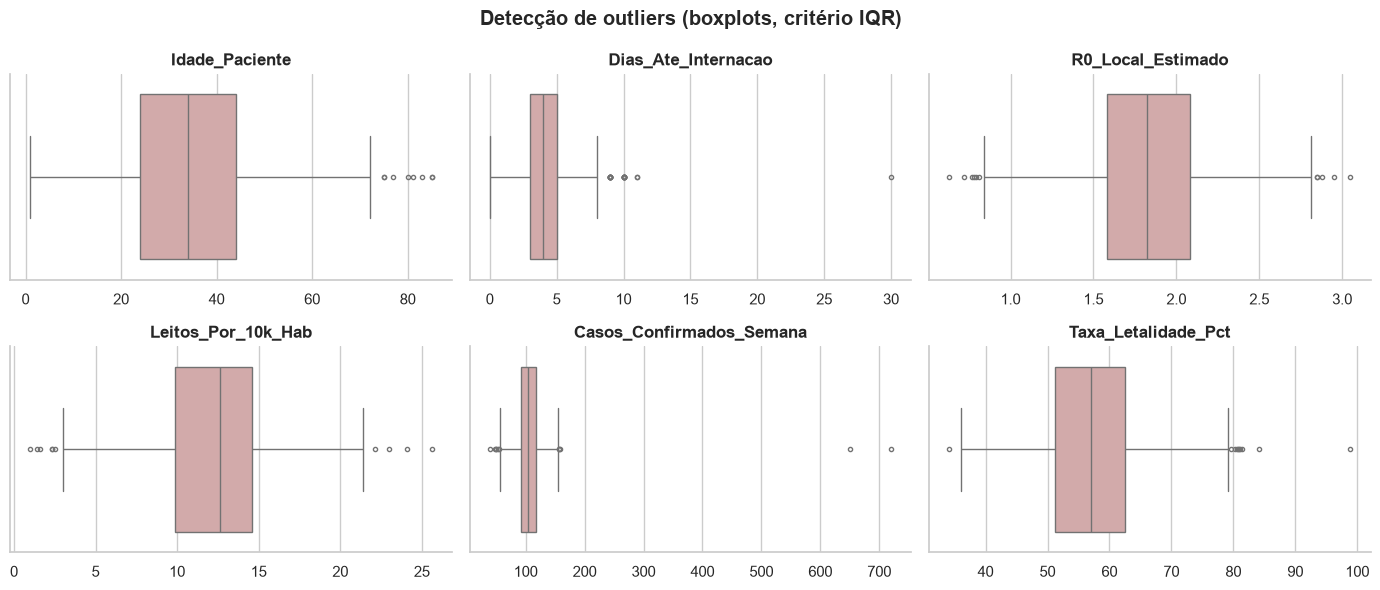

In [29]:
def detectar_outliers(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    por_iqr = (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)
    por_z = ((serie - serie.mean()) / serie.std()).abs() > 3
    return por_iqr, por_z


cols_num = ["Idade_Paciente", "Dias_Ate_Internacao", "R0_Local_Estimado",
            "Leitos_Por_10k_Hab", "Casos_Confirmados_Semana", "Taxa_Letalidade_Pct"]
linhas = []
for c in cols_num:
    iqr_f, z_f = detectar_outliers(df[c])
    linhas.append({"variavel": c, "outliers_IQR": int(iqr_f.sum()), "outliers_Z>3": int(z_f.sum())})
tabela_out = pd.DataFrame(linhas).set_index("variavel")
print(tabela_out)

fig, eixos = plt.subplots(2, 3, figsize=(14, 6))
for ax, c in zip(eixos.ravel(), cols_num):
    sns.boxplot(x=df[c], ax=ax, color="#d9a3a3", fliersize=3)
    ax.set_title(c)
    ax.set_xlabel("")
fig.suptitle("Detecção de outliers (boxplots, critério IQR)", fontweight="bold")
fig.tight_layout()
salvar(fig, "01_outliers")

df["Outlier_Extremo"] = False
for c in ["Dias_Ate_Internacao", "Casos_Confirmados_Semana", "Taxa_Letalidade_Pct"]:
    df["Outlier_Extremo"] |= detectar_outliers(df[c])[1]
df.loc[df["Outlier_Extremo"], ["ID_Registro", "Pais", "Dias_Ate_Internacao",
                               "Casos_Confirmados_Semana", "Taxa_Letalidade_Pct"]]

**Decisão:** os poucos extremos (picos de 650 e 720 casos/semana, uma internação em 30 dias, uma letalidade de 98,9%) são **sinalizados e mantidos** — podem ser eventos reais de surto — e testamos a robustez dos resultados com e sem eles.

### Engenharia de recursos

In [30]:
# Premissa externa: população aproximada (~2020) por país — a base não traz população.
POPULACAO = {"Guiné": 12.9e6, "Libéria": 5.1e6, "Serra Leoa": 8.0e6,
             "RDC (Congo)": 89.6e6, "Nigéria": 206.1e6, "Mali": 20.3e6, "Uganda": 45.7e6}

df["Mortes_Estimadas"] = df["Casos_Confirmados_Semana"] * df["Taxa_Letalidade_Pct"] / 100
df["Letalidade_Calc_Pct"] = df["Mortes_Estimadas"] / df["Casos_Confirmados_Semana"] * 100
assert np.allclose(df["Letalidade_Calc_Pct"], df["Taxa_Letalidade_Pct"])  # Mortes/Casos

df["Populacao"] = df["Pais"].map(POPULACAO)
df["Incidencia_100k"] = df["Casos_Confirmados_Semana"] / df["Populacao"] * 1e5

# Médias móveis sobre as notificações em ordem cronológica (a base não é diária:
# ~1 notificação a cada 4 dias, então 7 e 14 registros ≈ 4 e 8 semanas)
df["Casos_MM7"] = df["Casos_Confirmados_Semana"].rolling(7, min_periods=1).mean()
df["Casos_MM14"] = df["Casos_Confirmados_Semana"].rolling(14, min_periods=1).mean()

df["Onda"] = pd.cut(df["Ano"], bins=[2013, 2016, 2020, 2026],
                    labels=["Onda 1 (2014-16)", "Onda 2 (2017-20)", "Onda 3 (2021-26)"])
df["Faixa_Internacao"] = pd.cut(df["Dias_Ate_Internacao"], bins=[-1, 2, 4, 6, 100],
                                labels=["0-2 d", "3-4 d", "5-6 d", "7+ d"])
df[["Pais", "Casos_Confirmados_Semana", "Taxa_Letalidade_Pct", "Mortes_Estimadas",
    "Incidencia_100k", "Casos_MM7", "Casos_MM14", "Onda"]].head()

,Pais,Casos_Confirmados_Semana,Taxa_Letalidade_Pct,Mortes_Estimadas,Incidencia_100k,Casos_MM7,Casos_MM14,Onda
0,Guiné,39,68.32,26.6448,0.302326,39.0,39.0,Onda 1 (2014-16)
1,Serra Leoa,117,67.52,78.9984,1.462500,78.0,78.0,Onda 1 (2014-16)
2,Mali,105,58.32,61.2360,0.517241,87.0,87.0,Onda 1 (2014-16)
3,Guiné,105,63.09,66.2445,0.813953,91.5,91.5,Onda 1 (2014-16)
4,Serra Leoa,88,59.09,51.9992,1.100000,90.8,90.8,Onda 1 (2014-16)


## Etapa 2 — Análise exploratória
### 2.1 Evolução temporal

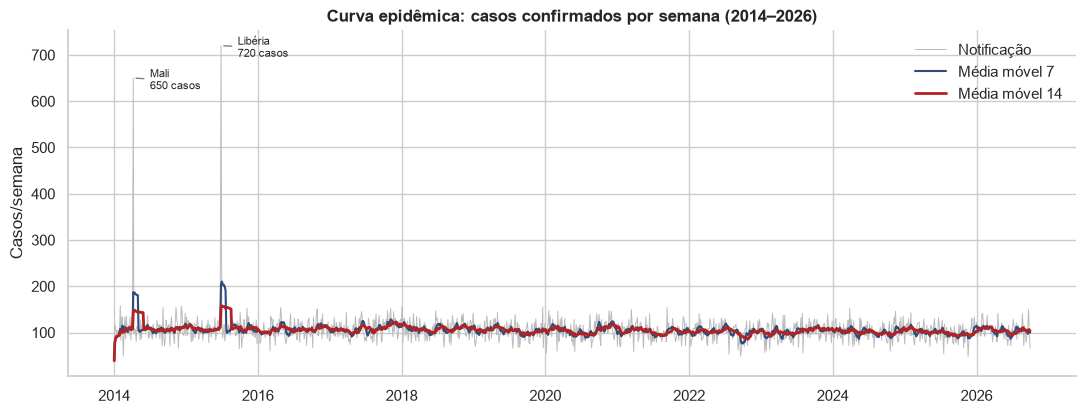

In [31]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(df["Data_Notificacao"], df["Casos_Confirmados_Semana"], color="#bbbbbb", lw=0.7, label="Notificação")
ax.plot(df["Data_Notificacao"], df["Casos_MM7"], color=COR2, lw=1.5, label="Média móvel 7")
ax.plot(df["Data_Notificacao"], df["Casos_MM14"], color=COR, lw=2, label="Média móvel 14")
for _, r in df.nlargest(2, "Casos_Confirmados_Semana").iterrows():
    ax.annotate(f"{r['Pais']}\n{int(r['Casos_Confirmados_Semana'])} casos", (r["Data_Notificacao"], r["Casos_Confirmados_Semana"]),
                xytext=(12, -8), textcoords="offset points", fontsize=8, arrowprops={"arrowstyle": "-", "color": "gray"})
ax.set_title("Curva epidêmica: casos confirmados por semana (2014–2026)")
ax.set_ylabel("Casos/semana")
ax.legend(frameon=False)
salvar(fig, "02_curva_epidemica")

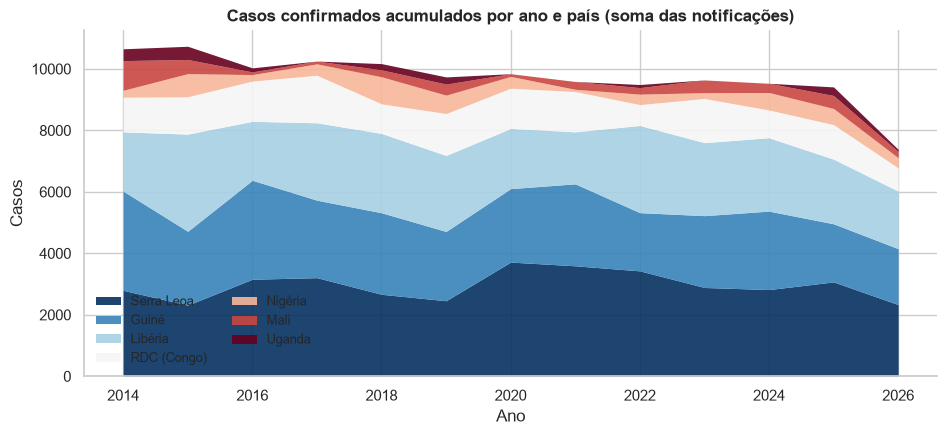

In [32]:
area = df.pivot_table(index="Ano", columns="Pais", values="Casos_Confirmados_Semana", aggfunc="sum")
ordem = area.sum().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 4.5))
area[ordem].plot.area(ax=ax, colormap="RdBu_r", alpha=0.9, lw=0)
ax.set_title("Casos confirmados acumulados por ano e país (soma das notificações)")
ax.set_ylabel("Casos")
ax.legend(frameon=False, ncol=2, fontsize=9)
salvar(fig, "03_area_pais_ano")

Tendência da letalidade: -0.300 p.p./ano (p=0.0001; R²=0.77)


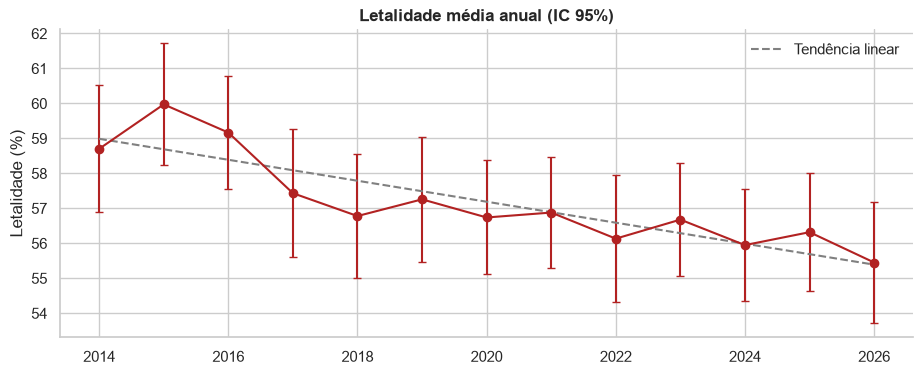

In [33]:
anual = df.groupby("Ano")["Taxa_Letalidade_Pct"].agg(["mean", "sem", "count"])
anual["ic"] = anual["sem"] * stats.t.ppf(0.975, anual["count"] - 1)
reg_ano = stats.linregress(anual.index, anual["mean"])
print(f"Tendência da letalidade: {reg_ano.slope:+.3f} p.p./ano (p={reg_ano.pvalue:.4f}; R²={reg_ano.rvalue**2:.2f})")
METRICAS["tendencia_letalidade_pp_ano"] = reg_ano.slope
METRICAS["tendencia_p"] = reg_ano.pvalue

fig, ax = plt.subplots(figsize=(11, 4))
ax.errorbar(anual.index, anual["mean"], yerr=anual["ic"], fmt="o-", color=COR, capsize=3)
ax.plot(anual.index, reg_ano.intercept + reg_ano.slope * anual.index, "--", color="gray", label="Tendência linear")
ax.set_title("Letalidade média anual (IC 95%)")
ax.set_ylabel("Letalidade (%)")
ax.legend(frameon=False)
salvar(fig, "04_letalidade_anual")

### 2.2 Comparação por país

In [34]:
paises = df.groupby("Pais").agg(
    registros=("ID_Registro", "count"),
    casos_totais=("Casos_Confirmados_Semana", "sum"),
    mortes_est=("Mortes_Estimadas", "sum"),
    letalidade_media=("Taxa_Letalidade_Pct", "mean"),
    letalidade_sem=("Taxa_Letalidade_Pct", "sem"),
    incidencia_100k_media=("Incidencia_100k", "mean"),
    dias_internacao=("Dias_Ate_Internacao", "mean"),
    leitos_10k=("Leitos_Por_10k_Hab", "mean"),
    r0=("R0_Local_Estimado", "mean"),
).sort_values("casos_totais", ascending=False)
paises.round(2)

,registros,casos_totais,mortes_est,letalidade_media,letalidade_sem,incidencia_100k_media,dias_internacao,leitos_10k,r0
Pais,,,,,,,,,
Serra Leoa,366,38452,22030.29,57.29,0.40,1.31,4.23,12.52,1.85
Guiné,306,31825,18056.54,56.72,0.49,0.81,4.19,11.87,1.81
Libéria,282,29806,17090.36,57.46,0.52,2.07,4.27,12.30,1.80
RDC (Congo),142,15042,8645.83,57.58,0.78,0.12,4.37,12.50,1.85
Nigéria,53,5447,3102.85,56.83,1.08,0.05,4.79,12.92,1.81
Mali,34,4080,2396.73,57.35,1.28,0.59,4.12,13.87,1.81
Uganda,17,1836,1086.33,58.91,2.47,0.24,4.71,12.59,1.93


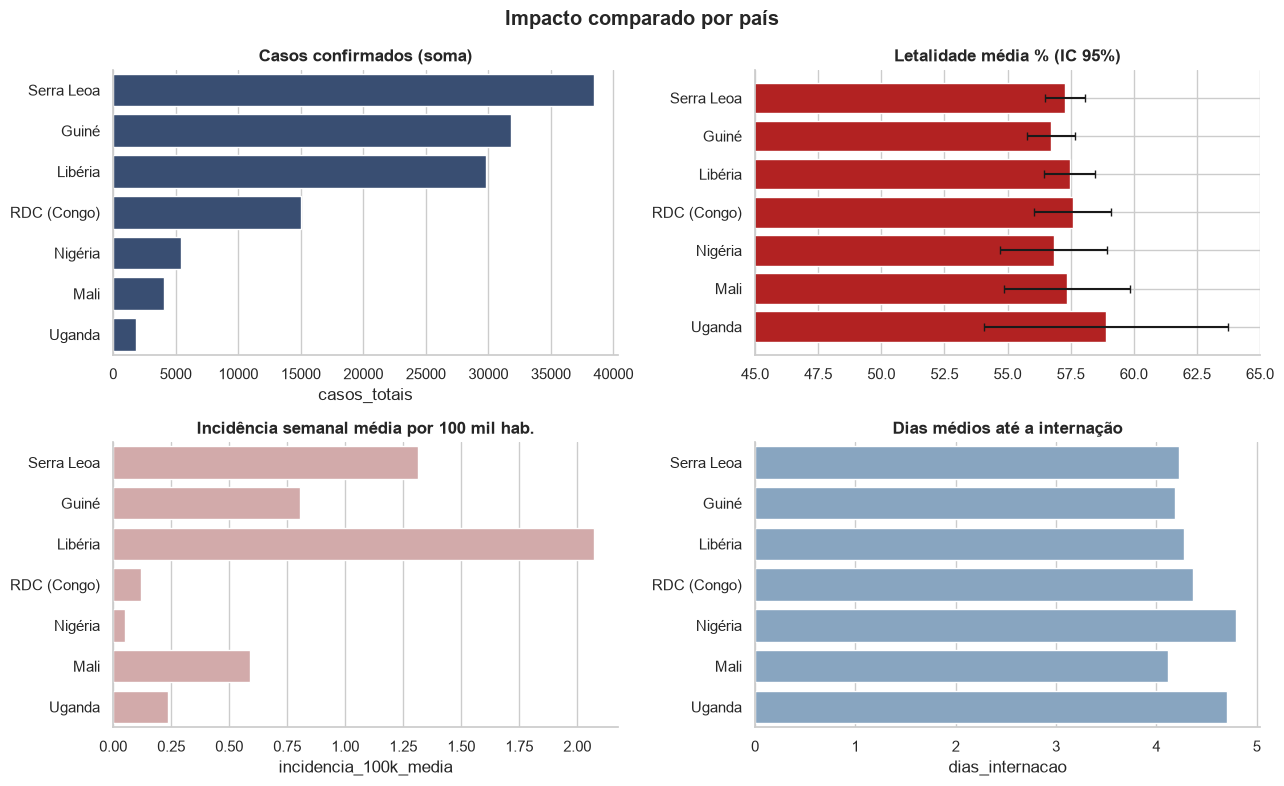

In [35]:
fig, eixos = plt.subplots(2, 2, figsize=(13, 8))
ordem = paises.index
sns.barplot(x=paises["casos_totais"], y=ordem, ax=eixos[0, 0], color=COR2)
eixos[0, 0].set_title("Casos confirmados (soma)")
eixos[0, 0].set_ylabel("")
eixos[0, 1].barh(ordem, paises["letalidade_media"], xerr=paises["letalidade_sem"] * 1.96, color=COR, capsize=3)
eixos[0, 1].set_xlim(45, 65)
eixos[0, 1].invert_yaxis()
eixos[0, 1].set_title("Letalidade média % (IC 95%)")
sns.barplot(x=paises["incidencia_100k_media"], y=ordem, ax=eixos[1, 0], color="#d9a3a3")
eixos[1, 0].set_title("Incidência semanal média por 100 mil hab.")
eixos[1, 0].set_ylabel("")
sns.barplot(x=paises["dias_internacao"], y=ordem, ax=eixos[1, 1], color="#7fa5c9")
eixos[1, 1].set_title("Dias médios até a internação")
eixos[1, 1].set_ylabel("")
fig.suptitle("Impacto comparado por país", fontweight="bold")
fig.tight_layout()
salvar(fig, "05_paises")

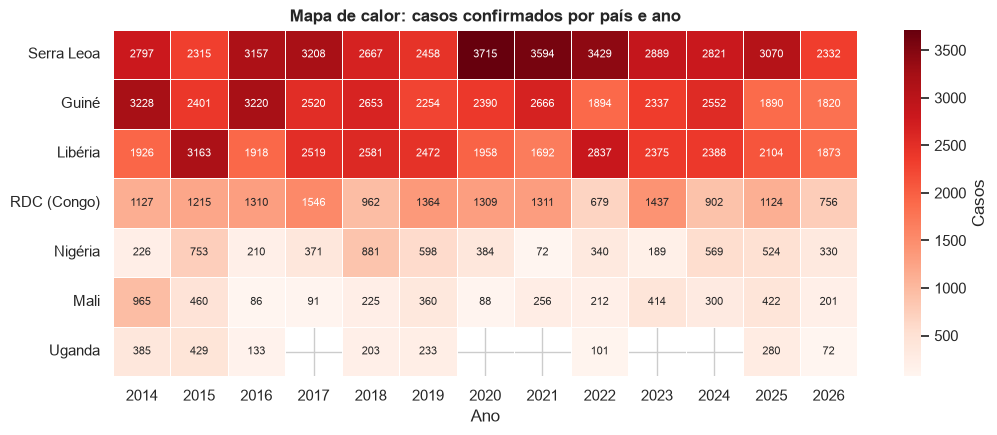

In [36]:
mapa = df.pivot_table(index="Pais", columns="Ano", values="Casos_Confirmados_Semana", aggfunc="sum").loc[ordem]
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(mapa, cmap="Reds", annot=True, fmt=".0f", annot_kws={"size": 8}, linewidths=0.5, ax=ax,
            cbar_kws={"label": "Casos"})
ax.set_title("Mapa de calor: casos confirmados por país e ano")
ax.set_ylabel("")
salvar(fig, "06_heatmap_pais_ano")

### 2.3 Correlações e distribuições

Idade_Paciente              0.02
Dias_Ate_Internacao         0.71
R0_Local_Estimado          -0.01
Leitos_Por_10k_Hab         -0.04
Casos_Confirmados_Semana    0.01
Incidencia_100k             0.00
Ano                        -0.13
Name: Taxa_Letalidade_Pct, dtype: float64

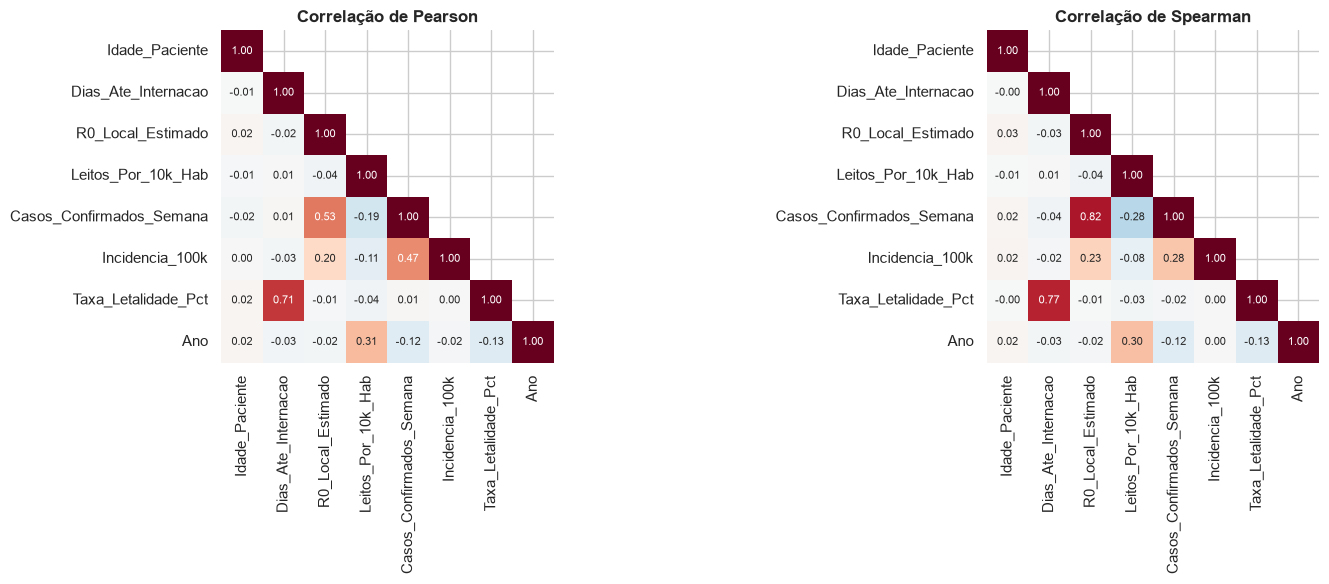

In [37]:
cols_corr = ["Idade_Paciente", "Dias_Ate_Internacao", "R0_Local_Estimado", "Leitos_Por_10k_Hab",
             "Casos_Confirmados_Semana", "Incidencia_100k", "Taxa_Letalidade_Pct", "Ano"]
fig, eixos = plt.subplots(1, 2, figsize=(16, 6))
for ax, met in zip(eixos, ["pearson", "spearman"]):
    corr = df[cols_corr].corr(method=met)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, square=True,
                cbar=False, annot_kws={"size": 8})
    ax.set_title(f"Correlação de {met.capitalize()}")
fig.tight_layout()
salvar(fig, "07_correlacao")
METRICAS["corr_dias_letalidade"] = df[["Dias_Ate_Internacao", "Taxa_Letalidade_Pct"]].corr().iloc[0, 1]
df[cols_corr].corr()["Taxa_Letalidade_Pct"].drop("Taxa_Letalidade_Pct").round(2)

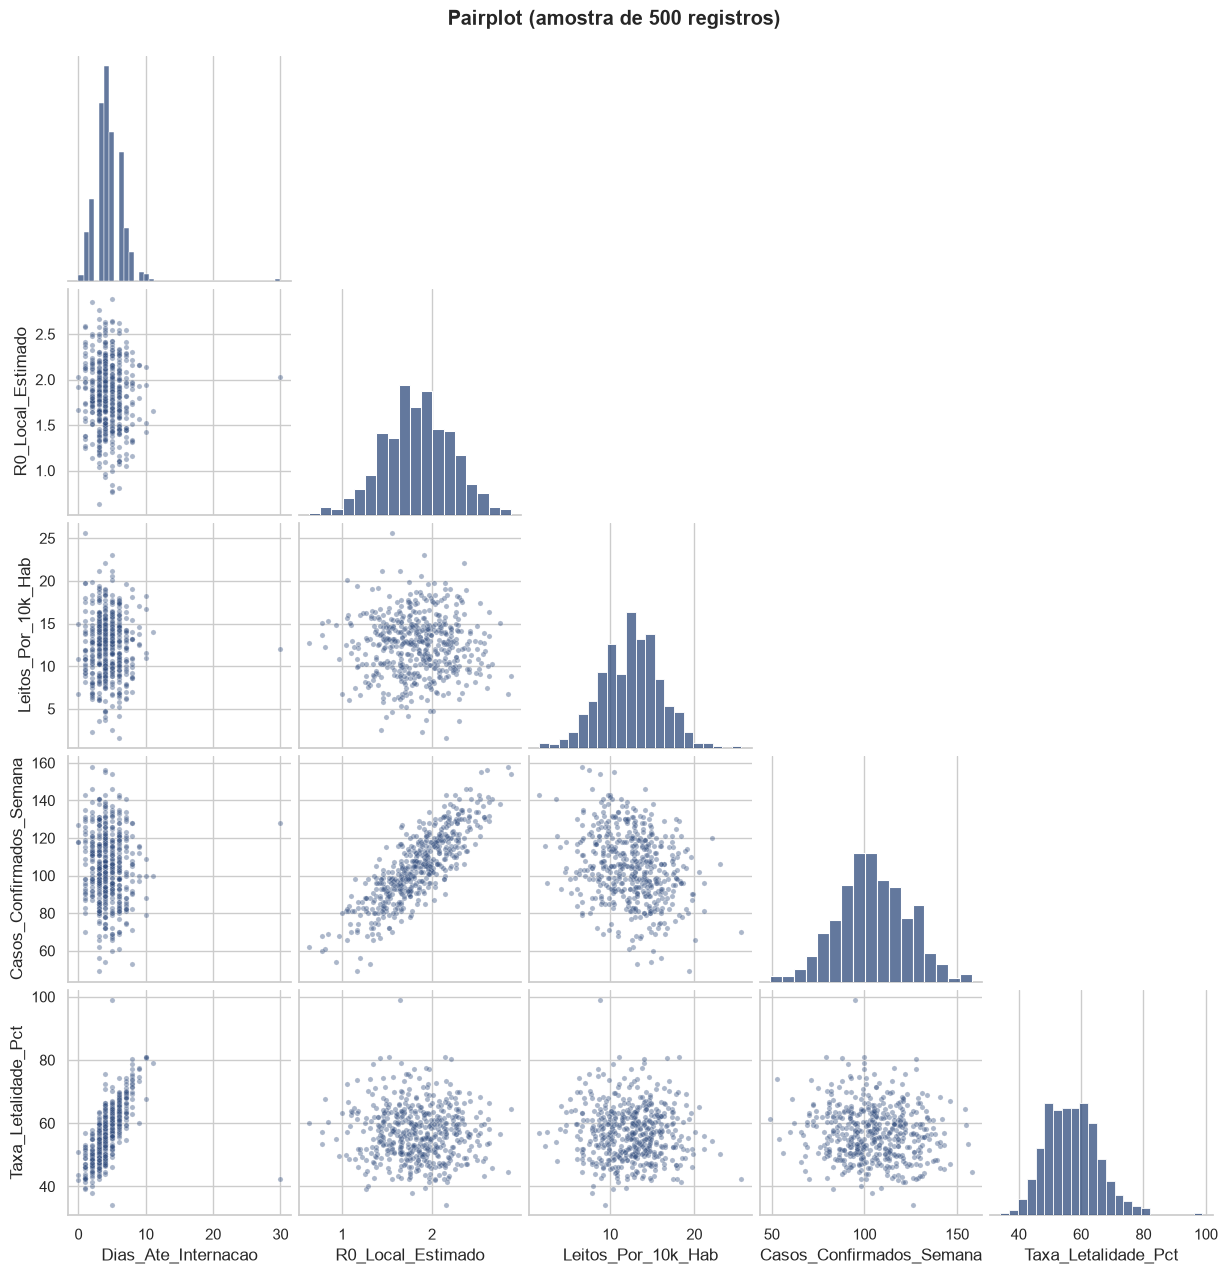

In [38]:
g = sns.pairplot(df[["Dias_Ate_Internacao", "R0_Local_Estimado", "Leitos_Por_10k_Hab",
                     "Casos_Confirmados_Semana", "Taxa_Letalidade_Pct"]].sample(500, random_state=1),
                 corner=True, plot_kws={"alpha": 0.4, "s": 14, "color": COR2}, diag_kws={"color": COR2})
g.figure.suptitle("Pairplot (amostra de 500 registros)", y=1.02, fontweight="bold")
salvar(g.figure, "08_pairplot")

,count,mean,std
Faixa_Internacao,,,
0-2 d,201,47.72,4.70
3-4 d,508,55.07,5.93
5-6 d,350,61.03,5.52
7+ d,141,69.07,6.25


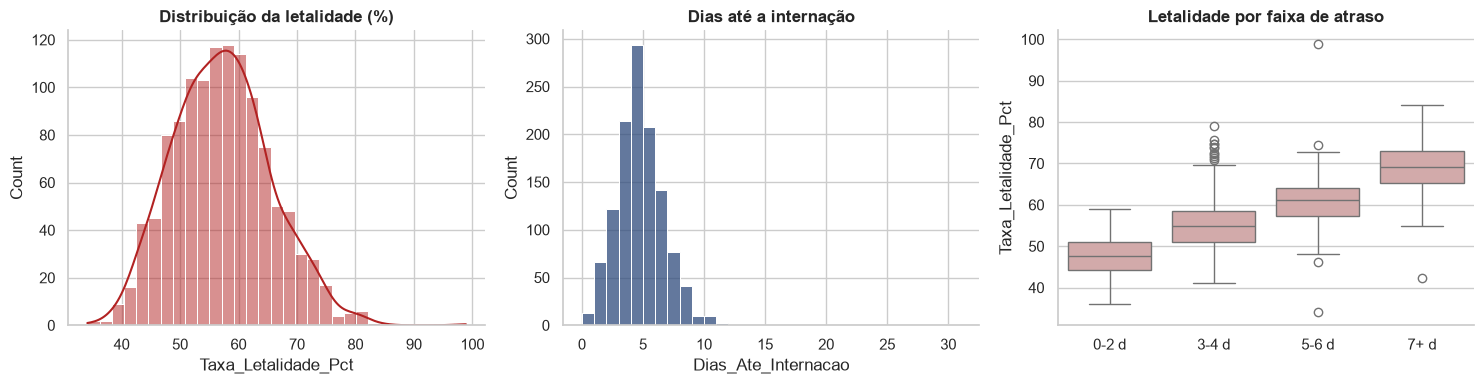

In [39]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["Taxa_Letalidade_Pct"], kde=True, color=COR, ax=eixos[0])
eixos[0].set_title("Distribuição da letalidade (%)")
sns.histplot(df["Dias_Ate_Internacao"], bins=range(0, 32), color=COR2, ax=eixos[1])
eixos[1].set_title("Dias até a internação")
sns.boxplot(data=df, x="Faixa_Internacao", y="Taxa_Letalidade_Pct", color="#d9a3a3", ax=eixos[2])
eixos[2].set_title("Letalidade por faixa de atraso")
eixos[2].set_xlabel("")
fig.tight_layout()
salvar(fig, "09_distribuicoes")
df.groupby("Faixa_Internacao", observed=True)["Taxa_Letalidade_Pct"].agg(["count", "mean", "std"]).round(2)

### Insights da EDA
- **Curva plana, com dois picos:** ~105 casos/semana por notificação ao longo de 13 anos; só 2014 (Mali, 650) e 2015 (Libéria, 720) fogem do padrão.
- **Concentração geográfica:** Serra Leoa, Guiné e Libéria somam ~79% dos casos (126.488 no total); com a RDC chegam a ~91%. A Libéria tem a maior incidência por 100 mil habitantes.
- **Letalidade parecida entre países** (56,7%–58,9%; diferenças dentro dos ICs; Uganda tem só 17 registros e IC largo).
- **A letalidade cai devagar:** −0,30 p.p. por ano (p < 0,001), de 58,7% (2014) para 55,5% (2026).
- **Um único fator se destaca:** o atraso até a internação (r ≈ 0,71 com a letalidade). R0 se associa a casos semanais (r ≈ 0,5), e leitos por 10 mil habitantes crescem com o tempo, mas quase não se relacionam com a letalidade.
- **Ressalva:** a regularidade da série (~94 notificações por ano) sugere uma base didática/simulada; conclusões operacionais reais exigiriam validação com dados oficiais.

## Etapa 3 — Inferência estatística
### 3.1 Teste t de Student: letalidade entre ondas do surto
Convenção analítica adotada (a base não traz ondas): **Onda 1** = 2014–2016, **Onda 2** = 2017–2020, **Onda 3** = 2021–2026.

Onda 1 (2014-16): n=283, média=59.28, dp=8.44, Shapiro-Wilk p=0.919
Onda 2 (2017-20): n=376, média=57.05, dp=8.56, Shapiro-Wilk p=0.000
Onda 3 (2021-26): n=541, média=56.27, dp=7.99, Shapiro-Wilk p=0.008

Teste t de Welch (p ajustado por Bonferroni, 3 comparações):
      comparação  dif_médias      t      p  p_bonf  d_Cohen
Onda 1 vs Onda 2      2.2261 3.3314 0.0009  0.0027   0.2616
Onda 1 vs Onda 3      3.0103 4.9510 0.0000  0.0000   0.3695
Onda 2 vs Onda 3      0.7842 1.4019 0.1613  0.4840   0.0953

ANOVA: F=12.40, p=0.00000 | Kruskal-Wallis (robusto): H=25.38, p=0.00000


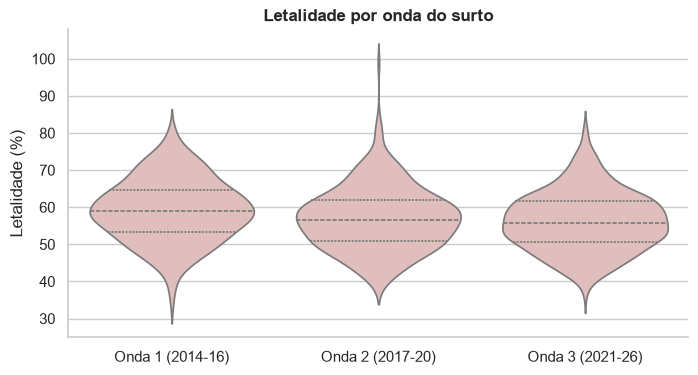

In [40]:
ondas = {o: g["Taxa_Letalidade_Pct"] for o, g in df.groupby("Onda", observed=True)}
for nome, s in ondas.items():
    w, p = stats.shapiro(s)
    print(f"{nome}: n={len(s)}, média={s.mean():.2f}, dp={s.std():.2f}, Shapiro-Wilk p={p:.3f}")


def cohen_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp


print("\nTeste t de Welch (p ajustado por Bonferroni, 3 comparações):")
nomes = list(ondas)
resultados_t = []
for i in range(3):
    for j in range(i + 1, 3):
        a, b = ondas[nomes[i]], ondas[nomes[j]]
        t, p = stats.ttest_ind(a, b, equal_var=False)
        resultados_t.append({"comparação": f"{nomes[i][:6]} vs {nomes[j][:6]}", "dif_médias": a.mean() - b.mean(),
                             "t": t, "p": p, "p_bonf": min(p * 3, 1), "d_Cohen": cohen_d(a, b)})
tabela_t = pd.DataFrame(resultados_t).round(4)
print(tabela_t.to_string(index=False))
F, p_anova = stats.f_oneway(*ondas.values())
H, p_kw = stats.kruskal(*ondas.values())
print(f"\nANOVA: F={F:.2f}, p={p_anova:.5f} | Kruskal-Wallis (robusto): H={H:.2f}, p={p_kw:.5f}")
METRICAS.update({"t_onda1_vs_2_p": float(resultados_t[0]["p"]), "t_onda1_vs_2_dif": float(resultados_t[0]["dif_médias"]),
                 "anova_p": float(p_anova), "ondas_medias": {k: float(v.mean()) for k, v in ondas.items()}})

fig, ax = plt.subplots(figsize=(8, 4))
sns.violinplot(data=df, x="Onda", y="Taxa_Letalidade_Pct", color="#e6b8b8", inner="quartile", ax=ax)
ax.set_title("Letalidade por onda do surto")
ax.set_xlabel("")
ax.set_ylabel("Letalidade (%)")
salvar(fig, "10_ondas")

**Leitura do teste t.** A letalidade média caiu entre as ondas: 59,3% (Onda 1) → 57,1% (Onda 2) → 56,3% (Onda 3). A diferença Onda 1 × Onda 2 é de 2,2 p.p. (p = 0,0009; 0,0027 com Bonferroni) e Onda 1 × Onda 3 é de 3,0 p.p. (p < 0,0001); Onda 2 × Onda 3 não difere (p = 0,16). ANOVA e Kruskal-Wallis confirmam (p < 0,001). O Shapiro-Wilk rejeita normalidade nas ondas 2 e 3 (por causa dos extremos), mas com centenas de observações o teste t é robusto e o Kruskal-Wallis (sem hipótese de normalidade) leva à mesma conclusão.
**Efeito pequeno (d de Cohen 0,26 a 0,37):** estatisticamente real, mas de poucos pontos percentuais.
\n\n# %% [markdown]
### 3.2 Qui-quadrado
A base não tem leitos de UTI nem sobrevivência individual. Proxies: **capacidade** = tercis de `Leitos_Por_10k_Hab`; **desfecho** = letalidade acima/abaixo da mediana. Como contraste, repetimos o teste para atraso na internação (≤ 3 dias vs ≥ 6 dias).

In [41]:
mediana_let = df["Taxa_Letalidade_Pct"].median()
df["Desfecho"] = np.where(df["Taxa_Letalidade_Pct"] >= mediana_let, "Letalidade alta", "Letalidade baixa")
df["Capacidade_Leitos"] = pd.qcut(df["Leitos_Por_10k_Hab"], 3, labels=["Baixa", "Média", "Alta"])


def qui_quadrado(linha, coluna, titulo):
    tab = pd.crosstab(linha, coluna)
    chi2, p, gl, _ = stats.chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    print(f"\n{titulo}\n{tab}\nχ²={chi2:.2f}, gl={gl}, p={p:.4g}, V de Cramér={v:.3f}")
    return chi2, p, v


_, p_leitos, v_leitos = qui_quadrado(df["Capacidade_Leitos"], df["Desfecho"], "Capacidade de leitos × desfecho")
sub = df[df["Dias_Ate_Internacao"].le(3) | df["Dias_Ate_Internacao"].ge(6)]
tempo = np.where(sub["Dias_Ate_Internacao"] <= 3, "Precoce (≤3 d)", "Tardia (≥6 d)")
_, p_tempo, v_tempo = qui_quadrado(pd.Series(tempo, index=sub.index, name="Internação"), sub["Desfecho"], "Atraso na internação × desfecho")
METRICAS.update({"chi_leitos_p": float(p_leitos), "chi_leitos_v": float(v_leitos),
                 "chi_tempo_p": float(p_tempo), "chi_tempo_v": float(v_tempo)})


Capacidade de leitos × desfecho
Desfecho           Letalidade alta  Letalidade baixa
Capacidade_Leitos                                   
Baixa                          208               194
Média                          202               207
Alta                           190               199
χ²=0.76, gl=2, p=0.6849, V de Cramér=0.025

Atraso na internação × desfecho
Desfecho        Letalidade alta  Letalidade baixa
Internação                                       
Precoce (≤3 d)               48               367
Tardia (≥6 d)               269                14
χ²=469.72, gl=1, p=3.678e-104, V de Cramér=0.820


**Leitura do qui-quadrado.** (i) Capacidade de leitos × desfecho: χ² = 0,76, p = 0,68, V = 0,03 → **sem associação**. Isso não prova que UTI seja irrelevante: leitos hospitalares por 10 mil habitantes é um proxy grosseiro (não mede UTI, qualidade nem tempo de acesso). (ii) Atraso na internação × desfecho: χ² = 469,7, p ≈ 10⁻¹⁰⁴, V = 0,82 → **associação muito forte**: 88% dos atendimentos precoces (≤ 3 d) ficam em letalidade baixa e 95% dos tardios (≥ 6 d) em letalidade alta. Como o teste compara extremos e descarta a faixa intermediária, o V de Cramér superestima a força média da relação; a regressão (3.4) é a medida mais honesta.

### 3.3 Intervalo de confiança de 95% para a média da `Taxa_Letalidade_Pct`

n = 1200
Média amostral = 57.224 %
Erro padrão (SEM) = 0.2413
IC 95% = [56.75 ; 57.70] %  (margem de erro ±0.47 p.p.)
5% dentro do IC? False | distância do limite inferior até 5%: 51.8 p.p.
Sem outliers IQR (n=1190): média=57.05, IC 95% = [56.59 ; 57.50]


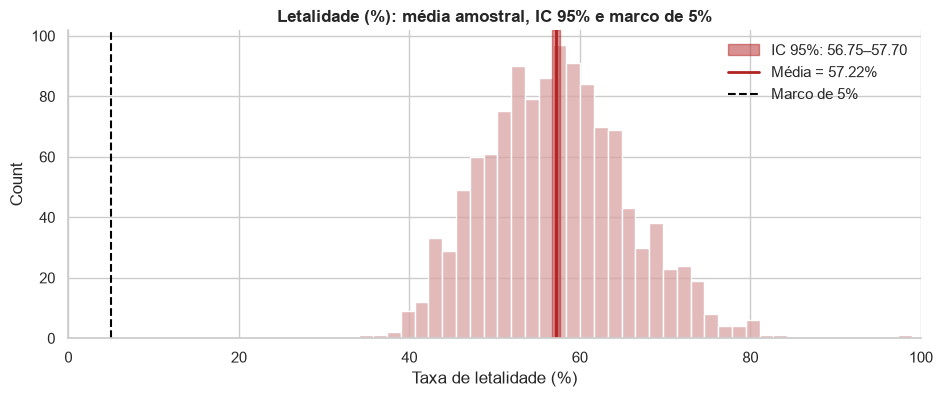

In [42]:
amostra = bruto["Taxa_Letalidade_Pct"].dropna()           # 1. carregamento e limpeza
n = len(amostra)                                          # 2. estatísticas amostrais
media = np.mean(amostra)
sem = stats.sem(amostra)
ic_inf, ic_sup = stats.t.interval(0.95, df=n - 1, loc=media, scale=sem)   # 3. IC t-Student

print(f"n = {n}")
print(f"Média amostral = {media:.3f} %")
print(f"Erro padrão (SEM) = {sem:.4f}")
print(f"IC 95% = [{ic_inf:.2f} ; {ic_sup:.2f}] %  (margem de erro ±{(ic_sup - ic_inf) / 2:.2f} p.p.)")
print("5% dentro do IC?", ic_inf <= 5 <= ic_sup, f"| distância do limite inferior até 5%: {ic_inf - 5:.1f} p.p.")

# Robustez: sem outliers pelo critério IQR
out_iqr, _ = detectar_outliers(amostra)
a2 = amostra[~out_iqr]
l2, u2 = stats.t.interval(0.95, df=len(a2) - 1, loc=a2.mean(), scale=stats.sem(a2))
print(f"Sem outliers IQR (n={len(a2)}): média={a2.mean():.2f}, IC 95% = [{l2:.2f} ; {u2:.2f}]")
METRICAS.update({"ci_n": n, "ci_media": float(media), "ci_sem": float(sem), "ci_inf": float(ic_inf), "ci_sup": float(ic_sup)})

fig, ax = plt.subplots(figsize=(11, 4))
sns.histplot(amostra, bins=40, color="#d9a3a3", ax=ax)
ax.axvspan(ic_inf, ic_sup, color=COR, alpha=0.5, label=f"IC 95%: {ic_inf:.2f}–{ic_sup:.2f}")
ax.axvline(media, color=COR, lw=2, label=f"Média = {media:.2f}%")
ax.axvline(5, color="black", ls="--", label="Marco de 5%")
ax.set_xlim(0, 100)
ax.set_title("Letalidade (%): média amostral, IC 95% e marco de 5%")
ax.set_xlabel("Taxa de letalidade (%)")
ax.legend(frameon=False)
salvar(fig, "11_intervalo_confianca")

**Interpretação do IC 95% (Data Storytelling).** Com n = 1.200, média = 57,22% e SEM = 0,24, o IC 95% é **[56,75% ; 57,70%]** (±0,47 p.p.). Se repetíssemos a coleta muitas vezes, ~95% dos intervalos assim construídos conteriria a verdadeira média; o nosso aponta que a letalidade típica gira em torno de 57%, ou seja, **mais de metade das pessoas notificadas morre**. Na prática: o intervalo é estreito, então a média é estimada com precisão, e qualquer meta de gestão deve partir de ~57%.
**O marco de 5% está fora do intervalo — a 51,8 p.p. do limite inferior.** A letalidade observada é mais de 11 vezes esse valor, de modo que 5% não é uma referência realista para o Ebola (a letalidade histórica reportada pela OMS fica entre ~25% e 90%, média em torno de 50%; mesmo essa média está abaixo do nosso limite inferior). Se o marco for usado como meta, a resposta atual está muito longe dela; se for um erro de digitação do enunciado, a conclusão se mantém ao comparar com ~50%. Ressalvas: o IC trata as notificações como independentes e sem ponderar por número de casos; como são séries no tempo, o erro padrão tende a ser otimista. Sem outliers (IQR) o resultado quase não muda: [56,59% ; 57,50%].
\n\n# %% [markdown]
### 3.4 Regressão linear simples: `Dias_Ate_Internacao` → `Taxa_Letalidade_Pct`

In [43]:
dados = bruto[["Dias_Ate_Internacao", "Taxa_Letalidade_Pct"]].dropna()
X = dados[["Dias_Ate_Internacao"]]
y = dados["Taxa_Letalidade_Pct"]

modelo = LinearRegression().fit(X, y)
b0, b1 = modelo.intercept_, modelo.coef_[0]
r2 = modelo.score(X, y)
print(f"n = {len(dados)}")
print(f"β0 (intercepto) = {b0:.3f}")
print(f"β1 (coef. angular) = {b1:.3f}")
print(f"R² = {r2:.4f}  (r2_score confere: {r2_score(y, modelo.predict(X)):.4f})")
print(f"Equação: ŷ = {b0:.2f} + {b1:.2f} · X")

previsao = float(modelo.predict(pd.DataFrame({"Dias_Ate_Internacao": [10]}))[0])
print(f"\nPrevisão para 10 dias: {previsao:.2f} %")

# Inferência adicional: erro-padrão do coeficiente e intervalos de previsão
lr = stats.linregress(X["Dias_Ate_Internacao"], y)
res = y - modelo.predict(X)
s_res = np.sqrt((res ** 2).sum() / (len(y) - 2))
sxx = ((X["Dias_Ate_Internacao"] - X["Dias_Ate_Internacao"].mean()) ** 2).sum()
tcrit = stats.t.ppf(0.975, len(y) - 2)
se_pred = s_res * np.sqrt(1 + 1 / len(y) + (10 - X["Dias_Ate_Internacao"].mean()) ** 2 / sxx)
se_med = s_res * np.sqrt(1 / len(y) + (10 - X["Dias_Ate_Internacao"].mean()) ** 2 / sxx)
print(f"IC 95% de β1: [{b1 - tcrit * lr.stderr:.2f} ; {b1 + tcrit * lr.stderr:.2f}] (p={lr.pvalue:.2g})")
print(f"IC 95% da letalidade média a 10 dias: [{previsao - tcrit * se_med:.1f} ; {previsao + tcrit * se_med:.1f}]")
print(f"Intervalo de previsão 95% (uma observação): [{previsao - tcrit * se_pred:.1f} ; {previsao + tcrit * se_pred:.1f}]")
print(f"Resíduo-padrão = {s_res:.2f} p.p. | observações com 10+ dias: {(X['Dias_Ate_Internacao'] >= 10).sum()}")

# Robustez 1: sem outliers (IQR) em X e y
mx, _ = detectar_outliers(X["Dias_Ate_Internacao"])
my, _ = detectar_outliers(y)
limpo = dados[~(mx | my)]
m2 = LinearRegression().fit(limpo[["Dias_Ate_Internacao"]], limpo["Taxa_Letalidade_Pct"])
print(f"\nSem outliers (n={len(limpo)}): β0={m2.intercept_:.2f}, β1={m2.coef_[0]:.2f}, "
      f"R²={m2.score(limpo[['Dias_Ate_Internacao']], limpo['Taxa_Letalidade_Pct']):.3f}, "
      f"previsão 10 d = {m2.predict(pd.DataFrame({'Dias_Ate_Internacao': [10]}))[0]:.1f}%")
# Robustez 2: validação cruzada 5-fold
cv = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print(f"R² em validação cruzada (5-fold): {cv.mean():.3f} ± {cv.std():.3f}")
METRICAS.update({"reg_n": len(dados), "reg_b0": float(b0), "reg_b1": float(b1), "reg_r2": float(r2),
                 "reg_pred10": previsao, "reg_pi_inf": float(previsao - tcrit * se_pred),
                 "reg_pi_sup": float(previsao + tcrit * se_pred), "reg_cv_r2": float(cv.mean()),
                 "reg_b1_inf": float(b1 - tcrit * lr.stderr), "reg_b1_sup": float(b1 + tcrit * lr.stderr),
                 "reg_b1_robusto": float(m2.coef_[0]), "reg_r2_robusto": float(m2.score(limpo[['Dias_Ate_Internacao']], limpo['Taxa_Letalidade_Pct']))})

n = 1116
β0 (intercepto) = 44.471
β1 (coef. angular) = 2.943
R² = 0.5507  (r2_score confere: 0.5507)
Equação: ŷ = 44.47 + 2.94 · X

Previsão para 10 dias: 73.90 %
IC 95% de β1: [2.79 ; 3.10] (p=9.1e-196)
IC 95% da letalidade média a 10 dias: [73.0 ; 74.9]
Intervalo de previsão 95% (uma observação): [62.9 ; 84.9]
Resíduo-padrão = 5.58 p.p. | observações com 10+ dias: 13

Sem outliers (n=1105): β0=42.38, β1=3.43, R²=0.667, previsão 10 d = 76.7%
R² em validação cruzada (5-fold): 0.489 ± 0.291


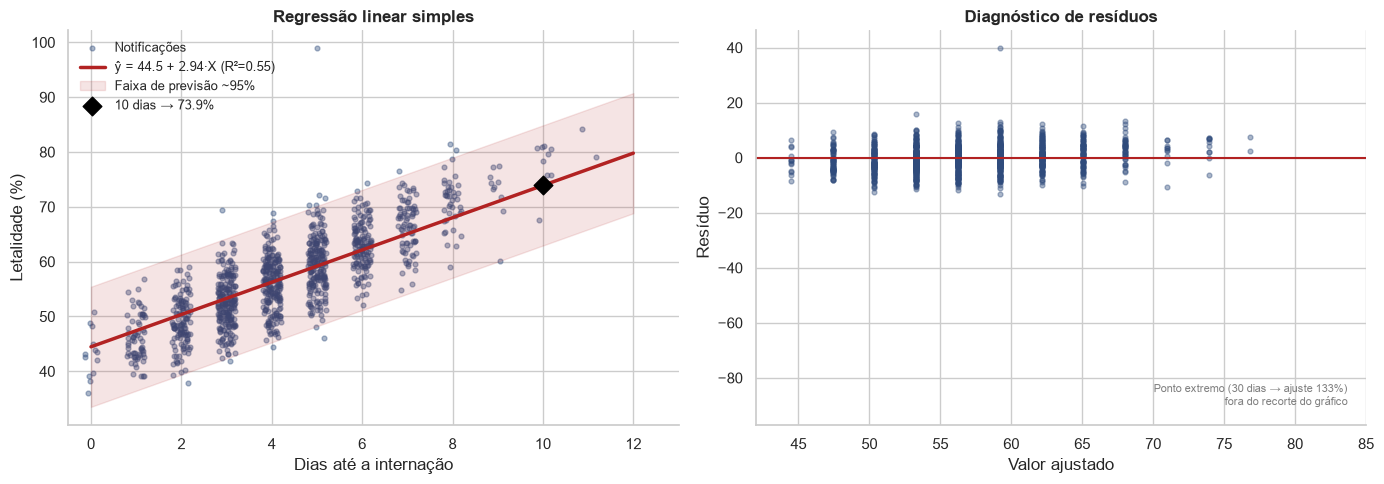

In [44]:
rng = np.random.default_rng(7)
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
ax = eixos[0]
ax.scatter(X["Dias_Ate_Internacao"] + rng.uniform(-0.2, 0.2, len(X)), y, s=12, alpha=0.4, color=COR2, label="Notificações")
xs = np.linspace(0, 12, 100)
ax.plot(xs, b0 + b1 * xs, color=COR, lw=2.5, label=f"ŷ = {b0:.1f} + {b1:.2f}·X (R²={r2:.2f})")
ax.fill_between(xs, b0 + b1 * xs - tcrit * s_res, b0 + b1 * xs + tcrit * s_res, color=COR, alpha=0.12,
                label="Faixa de previsão ~95%")
ax.scatter([10], [previsao], color="black", s=90, zorder=5, marker="D", label=f"10 dias → {previsao:.1f}%")
ax.set_xlim(-0.5, 13)
ax.set_xlabel("Dias até a internação")
ax.set_ylabel("Letalidade (%)")
ax.set_title("Regressão linear simples")
ax.legend(frameon=False, fontsize=9)
eixos[1].scatter(modelo.predict(X), res, s=12, alpha=0.4, color=COR2)
eixos[1].axhline(0, color=COR)
eixos[1].set_xlim(42, 85)
eixos[1].text(0.97, 0.05, "Ponto extremo (30 dias → ajuste 133%)\nfora do recorte do gráfico", transform=eixos[1].transAxes,
              ha="right", fontsize=8, color="gray")
eixos[1].set_xlabel("Valor ajustado")
eixos[1].set_ylabel("Resíduo")
eixos[1].set_title("Diagnóstico de resíduos")
fig.tight_layout()
salvar(fig, "12_regressao")

**Interpretação da regressão (Data Storytelling).** Equação: **ŷ = 44,47 + 2,94 · X** (n = 1.116, R² = 0,55).
- **β₁ = 2,94:** cada dia a mais até a internação se associa a **+2,94 p.p.** de letalidade (IC 95%: 2,79 a 3,10). Com β₀ = 44,5%, a letalidade esperada na internação imediata (dia 0).
- **R² = 0,55:** o tempo até a internação, sozinho, explica **~55%** da variação da letalidade. Os outros ~45% vêm de fatores não observados (idade, gravidade, carga viral, qualidade do cuidado) e de ruído. Em validação cruzada o R² médio cai para 0,49 ± 0,29 — a instabilidade vem de um único ponto de 30 dias; sem outliers o modelo fica mais forte (β₁ = 3,43; R² = 0,67).
- **Projeção para 10 dias:** **73,9%** (IC da média 73,0–74,9; intervalo de previsão para uma comunidade 62,9–84,9%). Só 13 registros têm 10+ dias, então esta é a região onde o modelo tem menos suporte; sem outliers a previsão sobe para 76,7%.
- **Recomendação à triagem:** dez dias de atraso é sinal de **alerta vermelho** (~74%, perto de 30 p.p. acima do dia 0). Priorizar busca ativa de casos, transporte até o centro de tratamento e fluxo de entrada sem filas; o alvo operacional é **internar em até 2 dias** (letalidade esperada ≈ 50,4%).
- **Cautela causal:** é uma associação observacional; pacientes mais graves podem chegar em tempos diferentes, e a relação não prova que antecipar a internação, sozinha, reduza a letalidade em 2,9 p.p. por dia.

## Clusterização (K-Means) — perfis de risco

 k  inércia  silhouette
 2   4637.0       0.218
 3   3751.0       0.212
 4   3321.0       0.188
 5   3002.0       0.189
 6   2732.0       0.195
 7   2510.0       0.196
 8   2373.0       0.188


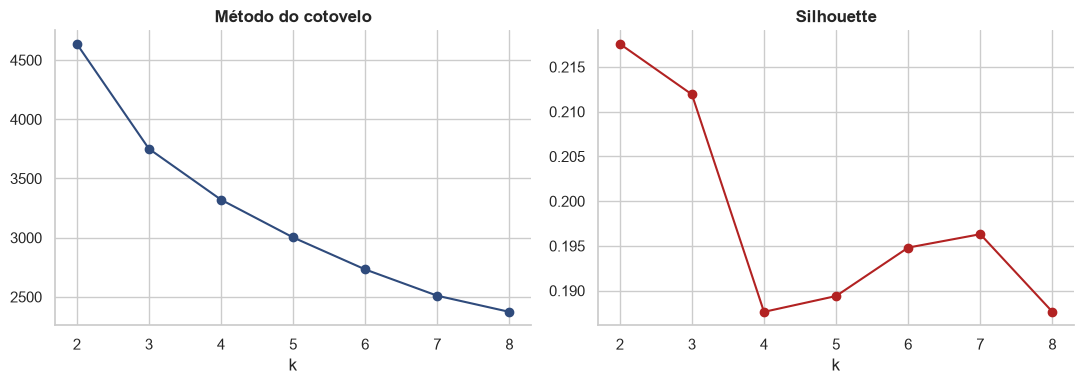

In [45]:
feats = ["Dias_Ate_Internacao", "R0_Local_Estimado", "Leitos_Por_10k_Hab", "Casos_Confirmados_Semana", "Taxa_Letalidade_Pct"]
Z = df[feats].copy()
Z["Casos_Confirmados_Semana"] = np.log1p(Z["Casos_Confirmados_Semana"])   # reduz o efeito dos picos
Zs = StandardScaler().fit_transform(Z)

ks = range(2, 9)
inercia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Zs)
    inercia.append(km.inertia_)
    sil.append(silhouette_score(Zs, km.labels_))
print(pd.DataFrame({"k": list(ks), "inércia": np.round(inercia, 0), "silhouette": np.round(sil, 3)}).to_string(index=False))

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].plot(list(ks), inercia, "o-", color=COR2)
eixos[0].set_title("Método do cotovelo")
eixos[0].set_xlabel("k")
eixos[1].plot(list(ks), sil, "o-", color=COR)
eixos[1].set_title("Silhouette")
eixos[1].set_xlabel("k")
fig.tight_layout()
salvar(fig, "13_cotovelo")

           n  dias    r0  leitos   casos  letalidade
Cluster                                             
0        475  3.55  2.12   11.25  122.46       54.35
1        366  6.28  1.73   12.25   99.98       65.94
2        359  3.19  1.54   13.94   88.38       52.14

Composição por país (% dentro do cluster):
Pais     Guiné  Libéria  Mali  Nigéria  RDC (Congo)  Serra Leoa  Uganda
Cluster                                                                
0         26.7     22.5   2.9      2.9         12.0        31.8     1.1
1         24.0     24.9   2.5      4.9         13.9        27.9     1.9
2         25.3     23.4   3.1      5.8          9.5        31.5     1.4


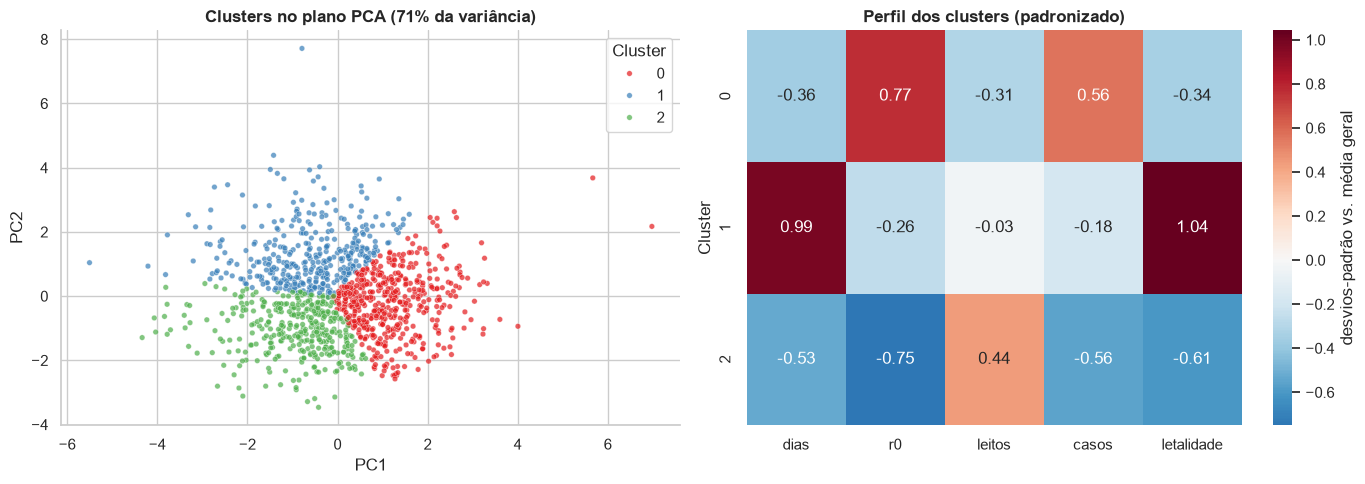

In [46]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Zs)
df["Cluster"] = km.labels_
perfil = df.groupby("Cluster").agg(n=("ID_Registro", "count"), dias=("Dias_Ate_Internacao", "mean"),
                                   r0=("R0_Local_Estimado", "mean"), leitos=("Leitos_Por_10k_Hab", "mean"),
                                   casos=("Casos_Confirmados_Semana", "mean"), letalidade=("Taxa_Letalidade_Pct", "mean"))
print(perfil.round(2))
print("\nComposição por país (% dentro do cluster):")
print((pd.crosstab(df["Cluster"], df["Pais"], normalize="index") * 100).round(1))
METRICAS["silhouette_k3"] = float(silhouette_score(Zs, km.labels_))

pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(Zs)
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df["Cluster"], palette="Set1", s=16, alpha=0.7, ax=eixos[0])
eixos[0].set_title(f"Clusters no plano PCA ({pca.explained_variance_ratio_.sum():.0%} da variância)")
eixos[0].set_xlabel("PC1")
eixos[0].set_ylabel("PC2")
perfil_z = (perfil[["dias", "r0", "leitos", "casos", "letalidade"]] - df[["Dias_Ate_Internacao", "R0_Local_Estimado", "Leitos_Por_10k_Hab", "Casos_Confirmados_Semana", "Taxa_Letalidade_Pct"]].mean().values) / df[["Dias_Ate_Internacao", "R0_Local_Estimado", "Leitos_Por_10k_Hab", "Casos_Confirmados_Semana", "Taxa_Letalidade_Pct"]].std().values
sns.heatmap(perfil_z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=eixos[1], cbar_kws={"label": "desvios-padrão vs. média geral"})
eixos[1].set_title("Perfil dos clusters (padronizado)")
fig.tight_layout()
salvar(fig, "14_clusters")

**Leitura dos clusters (K = 3, silhouette = 0,21 — separação fraca, adotada pela interpretabilidade).**
- **Cluster 1 · Internação tardia/alta letalidade (31% dos registros):** 6,3 dias até a internação e 65,9% de letalidade.
- **Cluster 0 · Transmissão intensa (40%):** R0 = 2,12 e ~122 casos/semana; internação rápida (3,6 d) e letalidade 54,4%.
- **Cluster 2 · Controlado (30%):** R0 = 1,54, mais leitos (13,9) e letalidade mais baixa (52,1%).
Os perfis **não seguem fronteiras de país** (cada país aparece em proporção parecida nos três grupos): o risco depende mais da operação (atraso, transmissão, capacidade) do que da geografia.

## Etapa 4 — Recomendações e plano de ação sanitária
| # | Ação | Alvo / público | Meta mensurável |
|---|------|----------------|-----------------|
| 1 | Fast-track de internação: busca ativa, transporte e triagem sem fila | Cluster 1 e países de maior volume | Mediana de dias até a internação de 4 → ≤ 2 em 12 meses; internação em ≤ 2 d de 17% → 50% dos casos |
| 2 | Protocolo "alerta vermelho" para casos com ≥ 7 dias de atraso (12% dos registros, letalidade média ≈ 69%) | Equipes de triagem em campo | Reduzir a fatia de 7+ d de 12% para < 5% |
| 3 | Contenção de transmissão: rastreio de contatos, isolamento e vacinação em anel | Cluster 0 (R0 ≈ 2,1) | R0 local < 1,5 |
| 4 | Concentrar recursos em Serra Leoa, Guiné e Libéria (~79% dos casos); atenção à incidência da Libéria | OMS / ministérios | 80% dos insumos nessas 3 áreas, revisão trimestral |
| 5 | Melhorar os dados: registrar óbitos, população, leitos de UTI e data de início dos sintomas; zerar a ausência de dias até internação (hoje 7%) | Vigilância epidemiológica | < 1% de dados ausentes |
| 6 | Campanha pública: sintomas, não tocar fluidos corporais, sepultamento seguro e buscar o serviço de saúde cedo | População em risco | Cartaz e mensagens em rádio e comunidades |

**Meta principal:** com a letalidade na casa dos 57%, o ganho esperado de reduzir 2 dias na internação é de ~5,9 p.p. (associação observada, não efeito garantido).

In [47]:
json.dump(METRICAS, open(FIGS / "metricas.json", "w"), indent=1, default=float)
df.to_csv("dados_tratados.csv", index=False)
METRICAS

{'tendencia_letalidade_pp_ano': np.float64(-0.29991568620959935),
 'tendencia_p': np.float64(7.480044733544683e-05),
 'corr_dias_letalidade': np.float64(0.7097397497842177),
 't_onda1_vs_2_p': 0.0009161871505598562,
 't_onda1_vs_2_dif': 2.2261048041500757,
 'anova_p': 4.6725214584162196e-06,
 'ondas_medias': {'Onda 1 (2014-16)': 59.27844522968199,
  'Onda 2 (2017-20)': 57.052340425531916,
  'Onda 3 (2021-26)': 56.26813308687615},
 'chi_leitos_p': 0.6849177285391153,
 'chi_leitos_v': 0.025114954119523854,
 'chi_tempo_p': 3.678220327741019e-104,
 'chi_tempo_v': 0.8203403410366883,
 'ci_n': 1200,
 'ci_media': 57.22378333333334,
 'ci_sem': 0.24125176038207993,
 'ci_inf': 56.7504607711464,
 'ci_sup': 57.697105895520274,
 'reg_n': 1116,
 'reg_b0': 44.470741021488685,
 'reg_b1': 2.9431836819074566,
 'reg_r2': 0.5507183288826769,
 'reg_pred10': 73.90257784056325,
 'reg_pi_inf': 62.90525764889924,
 'reg_pi_sup': 84.89989803222727,
 'reg_cv_r2': 0.48858929746849517,
 'reg_b1_inf': 2.786908663780